In [5]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load dataset
data = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["target"] = data.target

print("Dataset shape:", df.shape)

Dataset shape: (569, 31)


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Features and target
X = df.drop("target", axis=1)
y = df["target"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train_scaled.shape)
print("X_test :", X_test_scaled.shape)

X_train: (455, 30)
X_test : (114, 30)


In [8]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [9]:
y_pred=model.predict(X_test_scaled)
print(y_pred[:10])

[0 1 0 1 0 1 1 0 0 0]


In [10]:
y_prob = model.predict_proba(X_test_scaled)

print(y_prob[:5])

[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]]


In [11]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[41  1]
 [ 1 71]]


In [12]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.9824561403508771
Precision: 0.9861111111111112
Recall   : 0.9861111111111112
F1-Score : 0.9861111111111112


In [13]:
tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print("Specificity:", specificity)

Specificity: 0.9761904761904762


In [14]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_test, y_prob[:, 1])
pr_auc = average_precision_score(y_test, y_prob[:, 1])

print("ROC-AUC:", roc_auc)
print("PR-AUC :", pr_auc)

ROC-AUC: 0.9953703703703703
PR-AUC : 0.9970652078135953


In [15]:
results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "Specificity": [specificity],
    "F1-Score": [f1],
    "ROC-AUC": [roc_auc],
    "PR-AUC": [pr_auc]
})

results

,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.982456,0.986111,0.986111,0.97619,0.986111,0.99537,0.997065


<Figure size 600x500 with 0 Axes>

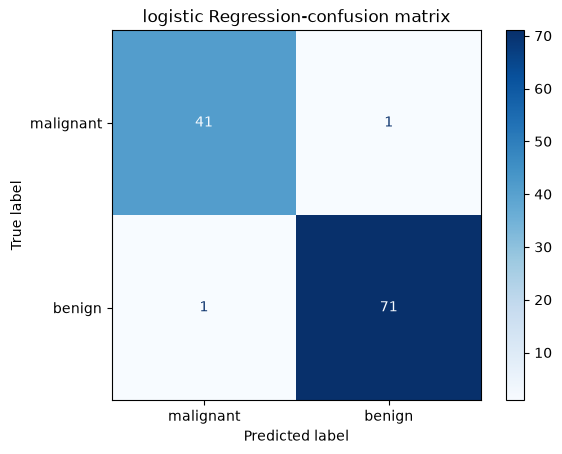

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["malignant","benign"]
).plot(cmap="Blues")

plt.title("logistic Regression-confusion matrix")
plt.show()

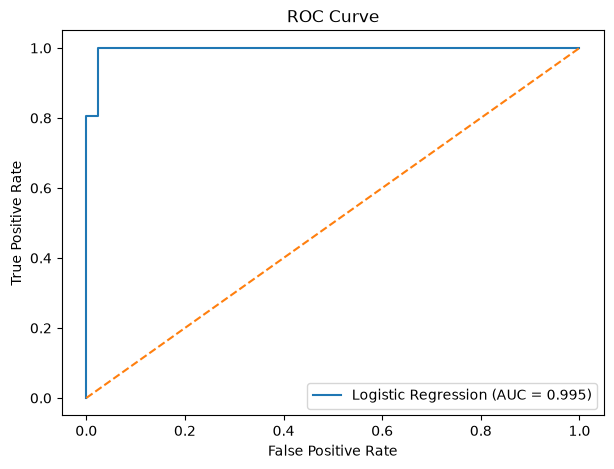

In [17]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob[:, 1]
)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

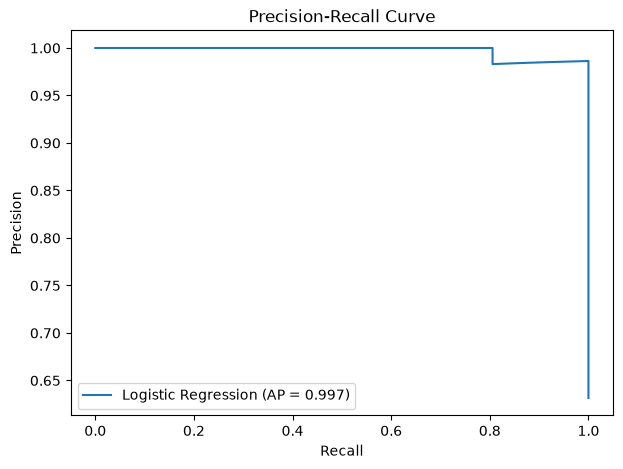

In [18]:
from sklearn.metrics import precision_recall_curve

precision_values, recall_values, thresholds = precision_recall_curve(
    y_test,
    y_prob[:, 1]
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"Logistic Regression (AP = {pr_auc:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

In [19]:
from sklearn.model_selection import StratifiedKFold,cross_val_score
from sklearn.linear_model import LogisticRegression
cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_model=LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [20]:
cv_scores=cross_val_score(
    lr_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring="accuracy"
)
print("Fold scores:", cv_scores)
print("Mean accuracy:", cv_scores.mean())
print("Std:", cv_scores.std())


Fold scores: [0.96703297 0.98901099 0.97802198 0.98901099 0.96703297]
Mean accuracy: 0.9780219780219781
Std: 0.009828870230768321


In [21]:
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    lr_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring=scoring
)

In [22]:
import pandas as pd

metrics_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Std": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

metrics_summary

,Metric,Mean,Std
0,Accuracy,0.978022,0.009829
1,Precision,0.979472,0.016229
2,Recall,0.985965,0.013129
3,F1,0.982544,0.007752
4,ROC-AUC,0.995666,0.004836


In [23]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information pr

In [24]:
print("Best C:", grid_search.best_params_["C"])
print("Best CV Accuracy:", grid_search.best_score_)

Best C: 0.1
Best CV Accuracy: 0.9824175824175825


In [25]:
best_lr = LogisticRegression(
    C=0.1,
    max_iter=1000,
    random_state=42
)

best_lr.fit(X_train_scaled, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [26]:
y_pred_tuned = best_lr.predict(X_test_scaled)
y_prob_tuned = best_lr.predict_proba(X_test_scaled)[:, 1]

In [27]:
from sklearn.metrics import accuracy_score, roc_auc_score

test_accuracy = accuracy_score(y_test, y_pred_tuned)
test_roc_auc = roc_auc_score(y_test, y_prob_tuned)

print("Test Accuracy:", test_accuracy)
print("Test ROC-AUC:", test_roc_auc)

Test Accuracy: 0.9736842105263158
Test ROC-AUC: 0.9957010582010581


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

tn, fp, fn, tp = cm_tuned.ravel()

test_specificity = tn / (tn + fp)

test_precision = precision_score(y_test, y_pred_tuned)
test_recall = recall_score(y_test, y_pred_tuned)
test_f1 = f1_score(y_test, y_pred_tuned)
test_pr_auc = average_precision_score(y_test, y_prob_tuned)

print("Accuracy    :", test_accuracy)
print("Precision   :", test_precision)
print("Recall      :", test_recall)
print("Specificity :", test_specificity)
print("F1-Score    :", test_f1)
print("ROC-AUC     :", test_roc_auc)
print("PR-AUC      :", test_pr_auc)

Accuracy    : 0.9736842105263158
Precision   : 0.9726027397260274
Recall      : 0.9861111111111112
Specificity : 0.9523809523809523
F1-Score    : 0.9793103448275862
ROC-AUC     : 0.9957010582010581
PR-AUC      : 0.9974281134887386


In [29]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [30]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

cm_rf = confusion_matrix(y_test, y_pred_rf)

tn, fp, fn, tp = cm_rf.ravel()

specificity_rf = tn / (tn + fp)

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("Accuracy    :", accuracy_rf)
print("Precision   :", precision_rf)
print("Recall      :", recall_rf)
print("Specificity :", specificity_rf)
print("F1-Score    :", f1_rf)
print("ROC-AUC     :", roc_auc_rf)
print("PR-AUC      :", pr_auc_rf)

Accuracy    : 0.956140350877193
Precision   : 0.958904109589041
Recall      : 0.9722222222222222
Specificity : 0.9285714285714286
F1-Score    : 0.9655172413793104
ROC-AUC     : 0.9937169312169312
PR-AUC      : 0.9962156701101823


In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

rf_cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

In [33]:
rf_cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        rf_cv_results["test_accuracy"].mean(),
        rf_cv_results["test_precision"].mean(),
        rf_cv_results["test_recall"].mean(),
        rf_cv_results["test_f1"].mean(),
        rf_cv_results["test_roc_auc"].mean()
    ],
    "Std": [
        rf_cv_results["test_accuracy"].std(),
        rf_cv_results["test_precision"].std(),
        rf_cv_results["test_recall"].std(),
        rf_cv_results["test_f1"].std(),
        rf_cv_results["test_roc_auc"].std()
    ]
})

rf_cv_summary

,Metric,Mean,Std
0,Accuracy,0.962637,0.017855
1,Precision,0.975519,0.017177
2,Recall,0.964912,0.024811
3,F1,0.969935,0.014605
4,ROC-AUC,0.989577,0.008257


In [34]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)
print("Best parameters:", rf_grid.best_params_)
print("Best CV Accuracy:", rf_grid.best_score_)

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Accuracy: 0.9626373626373628


In [35]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)
y_prob_rf_tuned = best_rf.predict_proba(X_test)[:, 1]
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
precision_rf_tuned = precision_score(y_test, y_pred_rf_tuned)
recall_rf_tuned = recall_score(y_test, y_pred_rf_tuned)
f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned)

cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)

tn, fp, fn, tp = cm_rf_tuned.ravel()

specificity_rf_tuned = tn / (tn + fp)

roc_auc_rf_tuned = roc_auc_score(y_test, y_prob_rf_tuned)
pr_auc_rf_tuned = average_precision_score(y_test, y_prob_rf_tuned)

print("Accuracy    :", accuracy_rf_tuned)
print("Precision   :", precision_rf_tuned)
print("Recall      :", recall_rf_tuned)
print("Specificity :", specificity_rf_tuned)
print("F1-Score    :", f1_rf_tuned)
print("ROC-AUC     :", roc_auc_rf_tuned)
print("PR-AUC      :", pr_auc_rf_tuned)

Accuracy    : 0.956140350877193
Precision   : 0.958904109589041
Recall      : 0.9722222222222222
Specificity : 0.9285714285714286
F1-Score    : 0.9655172413793104
ROC-AUC     : 0.9937169312169312
PR-AUC      : 0.9962156701101823


In [36]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

c:\Users\User\Desktop\medical tabular ml pipeline\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [37]:
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

cm_svm = confusion_matrix(y_test, y_pred_svm)

tn, fp, fn, tp = cm_svm.ravel()

specificity_svm = tn / (tn + fp)

roc_auc_svm = roc_auc_score(y_test, y_prob_svm)
pr_auc_svm = average_precision_score(y_test, y_prob_svm)

print("Accuracy    :", accuracy_svm)
print("Precision   :", precision_svm)
print("Recall      :", recall_svm)
print("Specificity :", specificity_svm)
print("F1-Score    :", f1_svm)
print("ROC-AUC     :", roc_auc_svm)
print("PR-AUC      :", pr_auc_svm)

Accuracy    : 0.9824561403508771
Precision   : 0.9861111111111112
Recall      : 0.9861111111111112
Specificity : 0.9761904761904762
F1-Score    : 0.9861111111111112
ROC-AUC     : 0.9950396825396826
PR-AUC      : 0.9969313924914238


In [39]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

svm_cv_results = cross_validate(
    svm_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring=scoring
)

c:\Users\User\Desktop\medical tabular ml pipeline\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\Desktop\medical tabular ml pipeline\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\Desktop\medical tabular ml pipeline\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\User\Desktop\medical tabular ml pipeline\.venv\Lib\site-packages\sklearn\

In [40]:
svm_cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        svm_cv_results["test_accuracy"].mean(),
        svm_cv_results["test_precision"].mean(),
        svm_cv_results["test_recall"].mean(),
        svm_cv_results["test_f1"].mean(),
        svm_cv_results["test_roc_auc"].mean()
    ],
    "Std": [
        svm_cv_results["test_accuracy"].std(),
        svm_cv_results["test_precision"].std(),
        svm_cv_results["test_recall"].std(),
        svm_cv_results["test_f1"].std(),
        svm_cv_results["test_roc_auc"].std()
    ]
})

svm_cv_summary

,Metric,Mean,Std
0,Accuracy,0.967033,0.015541
1,Precision,0.972685,0.022499
2,Recall,0.975439,0.017891
3,F1,0.973782,0.012165
4,ROC-AUC,0.995666,0.004825


In [41]:
from sklearn.model_selection import GridSearchCV

svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.01, 0.1, 1]
}

svm_grid = GridSearchCV(
    estimator=SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),
    param_grid=svm_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train_scaled, y_train)

c:\Users\User\Desktop\medical tabular ml pipeline\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(probabili...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': ['scale', 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the

In [42]:
print("Best parameters:", svm_grid.best_params_)
print("Best CV Accuracy:", svm_grid.best_score_)

Best parameters: {'C': 10, 'gamma': 0.01}
Best CV Accuracy: 0.9758241758241759


In [43]:
best_svm = svm_grid.best_estimator_

y_pred_svm_tuned = best_svm.predict(X_test_scaled)
y_prob_svm_tuned = best_svm.predict_proba(X_test_scaled)[:, 1]

In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

accuracy_svm_tuned = accuracy_score(y_test, y_pred_svm_tuned)
precision_svm_tuned = precision_score(y_test, y_pred_svm_tuned)
recall_svm_tuned = recall_score(y_test, y_pred_svm_tuned)
f1_svm_tuned = f1_score(y_test, y_pred_svm_tuned)

cm_svm_tuned = confusion_matrix(y_test, y_pred_svm_tuned)

tn, fp, fn, tp = cm_svm_tuned.ravel()

specificity_svm_tuned = tn / (tn + fp)

roc_auc_svm_tuned = roc_auc_score(
    y_test,
    y_prob_svm_tuned
)

pr_auc_svm_tuned = average_precision_score(
    y_test,
    y_prob_svm_tuned
)

print("Accuracy    :", accuracy_svm_tuned)
print("Precision   :", precision_svm_tuned)
print("Recall      :", recall_svm_tuned)
print("Specificity :", specificity_svm_tuned)
print("F1-Score    :", f1_svm_tuned)
print("ROC-AUC     :", roc_auc_svm_tuned)
print("PR-AUC      :", pr_auc_svm_tuned)

Accuracy    : 0.9824561403508771
Precision   : 0.9861111111111112
Recall      : 0.9861111111111112
Specificity : 0.9761904761904762
F1-Score    : 0.9861111111111112
ROC-AUC     : 0.9976851851851851
PR-AUC      : 0.9986099757018846


In [45]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [46]:
y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

tn, fp, fn, tp = cm_xgb.ravel()

specificity_xgb = tn / (tn + fp)

roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)
pr_auc_xgb = average_precision_score(y_test, y_prob_xgb)

print("Accuracy    :", accuracy_xgb)
print("Precision   :", precision_xgb)
print("Recall      :", recall_xgb)
print("Specificity :", specificity_xgb)
print("F1-Score    :", f1_xgb)
print("ROC-AUC     :", roc_auc_xgb)
print("PR-AUC      :", pr_auc_xgb)

Accuracy    : 0.9473684210526315
Precision   : 0.9459459459459459
Recall      : 0.9722222222222222
Specificity : 0.9047619047619048
F1-Score    : 0.958904109589041
ROC-AUC     : 0.9933862433862434
PR-AUC      : 0.996208108736925


In [48]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

xgb_cv_results = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

In [49]:
xgb_cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        xgb_cv_results["test_accuracy"].mean(),
        xgb_cv_results["test_precision"].mean(),
        xgb_cv_results["test_recall"].mean(),
        xgb_cv_results["test_f1"].mean(),
        xgb_cv_results["test_roc_auc"].mean()
    ],
    "Std": [
        xgb_cv_results["test_accuracy"].std(),
        xgb_cv_results["test_precision"].std(),
        xgb_cv_results["test_recall"].std(),
        xgb_cv_results["test_f1"].std(),
        xgb_cv_results["test_roc_auc"].std()
    ]
})

xgb_cv_summary

,Metric,Mean,Std
0,Accuracy,0.971429,0.017855
1,Precision,0.979239,0.020016
2,Recall,0.975439,0.017891
3,F1,0.977173,0.014244
4,ROC-AUC,0.993086,0.004977


In [50]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ),
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [2, 3, ...], 'n_estimators': [100, 200], 'subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

In [51]:
print("Best parameters:", xgb_grid.best_params_)
print("Best CV Accuracy:", xgb_grid.best_score_)

Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}
Best CV Accuracy: 0.9714285714285715


In [52]:
best_xgb = xgb_grid.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_test)
y_prob_xgb_tuned = best_xgb.predict_proba(X_test)[:, 1]

In [53]:
accuracy_xgb_tuned = accuracy_score(y_test, y_pred_xgb_tuned)
precision_xgb_tuned = precision_score(y_test, y_pred_xgb_tuned)
recall_xgb_tuned = recall_score(y_test, y_pred_xgb_tuned)
f1_xgb_tuned = f1_score(y_test, y_pred_xgb_tuned)

cm_xgb_tuned = confusion_matrix(y_test, y_pred_xgb_tuned)

tn, fp, fn, tp = cm_xgb_tuned.ravel()

specificity_xgb_tuned = tn / (tn + fp)

roc_auc_xgb_tuned = roc_auc_score(
    y_test,
    y_prob_xgb_tuned
)

pr_auc_xgb_tuned = average_precision_score(
    y_test,
    y_prob_xgb_tuned
)

print("Accuracy    :", accuracy_xgb_tuned)
print("Precision   :", precision_xgb_tuned)
print("Recall      :", recall_xgb_tuned)
print("Specificity :", specificity_xgb_tuned)
print("F1-Score    :", f1_xgb_tuned)
print("ROC-AUC     :", roc_auc_xgb_tuned)
print("PR-AUC      :", pr_auc_xgb_tuned)

Accuracy    : 0.9473684210526315
Precision   : 0.9459459459459459
Recall      : 0.9722222222222222
Specificity : 0.9047619047619048
F1-Score    : 0.958904109589041
ROC-AUC     : 0.9927248677248678
PR-AUC      : 0.9958085807304669


In [54]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM",
        "XGBoost"
    ],

    "CV Accuracy": [
        grid_search.best_score_,
        rf_grid.best_score_,
        svm_grid.best_score_,
        xgb_grid.best_score_
    ],

    "Test Accuracy": [
        test_accuracy,
        accuracy_rf_tuned,
        accuracy_svm_tuned,
        accuracy_xgb_tuned
    ],

    "Precision": [
        test_precision,
        precision_rf_tuned,
        precision_svm_tuned,
        precision_xgb_tuned
    ],

    "Recall": [
        test_recall,
        recall_rf_tuned,
        recall_svm_tuned,
        recall_xgb_tuned
    ],

    "Specificity": [
        test_specificity,
        specificity_rf_tuned,
        specificity_svm_tuned,
        specificity_xgb_tuned
    ],

    "F1": [
        test_f1,
        f1_rf_tuned,
        f1_svm_tuned,
        f1_xgb_tuned
    ],

    "ROC-AUC": [
        test_roc_auc,
        roc_auc_rf_tuned,
        roc_auc_svm_tuned,
        roc_auc_xgb_tuned
    ],

    "PR-AUC": [
        test_pr_auc,
        pr_auc_rf_tuned,
        pr_auc_svm_tuned,
        pr_auc_xgb_tuned
    ]
})

comparison

,Model,CV Accuracy,Test Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.982418,0.973684,0.972603,0.986111,0.952381,0.979310,0.995701,0.997428
1,Random Forest,0.962637,0.956140,0.958904,0.972222,0.928571,0.965517,0.993717,0.996216
2,SVM,0.975824,0.982456,0.986111,0.986111,0.976190,0.986111,0.997685,0.998610
3,XGBoost,0.971429,0.947368,0.945946,0.972222,0.904762,0.958904,0.992725,0.995809


In [55]:
comparison_percent = comparison.copy()

metric_columns = [
    "CV Accuracy",
    "Test Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

comparison_percent[metric_columns] = (
    comparison_percent[metric_columns] * 100
).round(2)

comparison_percent

,Model,CV Accuracy,Test Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,PR-AUC
0,Logistic Regression,98.24,97.37,97.26,98.61,95.24,97.93,99.57,99.74
1,Random Forest,96.26,95.61,95.89,97.22,92.86,96.55,99.37,99.62
2,SVM,97.58,98.25,98.61,98.61,97.62,98.61,99.77,99.86
3,XGBoost,97.14,94.74,94.59,97.22,90.48,95.89,99.27,99.58


In [56]:
from sklearn.metrics import confusion_matrix

models_predictions = {
    "Logistic Regression": y_pred_tuned,
    "Random Forest": y_pred_rf_tuned,
    "SVM": y_pred_svm_tuned,
    "XGBoost": y_pred_xgb_tuned
}

malignant_results = []

for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    tn, fp, fn, tp = cm.ravel()

    # Malignant = class 0
    malignant_sensitivity = tn / (tn + fp)

    # Benign = class 1
    benign_sensitivity = tp / (tp + fn)

    malignant_results.append({
        "Model": model_name,
        "Malignant Sensitivity": malignant_sensitivity,
        "Benign Sensitivity": benign_sensitivity,
        "Malignant Missed (FN)": fp
    })

malignant_df = pd.DataFrame(malignant_results)

malignant_df

,Model,Malignant Sensitivity,Benign Sensitivity,Malignant Missed (FN)
0,Logistic Regression,0.952381,0.986111,2
1,Random Forest,0.928571,0.972222,3
2,SVM,0.976190,0.986111,1
3,XGBoost,0.904762,0.972222,4


In [57]:
for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    tn, fp, fn, tp = cm.ravel()

    print(f"\n{model_name}")
    print("Malignant correctly identified:", tn)
    print("Malignant missed:", fp)


Logistic Regression
Malignant correctly identified: 40
Malignant missed: 2

Random Forest
Malignant correctly identified: 39
Malignant missed: 3

SVM
Malignant correctly identified: 41
Malignant missed: 1

XGBoost
Malignant correctly identified: 38
Malignant missed: 4


In [58]:
import numpy as np

test_results = pd.DataFrame({
    "Actual": y_test.values,
    "Logistic": y_pred_tuned,
    "RandomForest": y_pred_rf_tuned,
    "SVM": y_pred_svm_tuned,
    "XGBoost": y_pred_xgb_tuned
}, index=X_test.index)

# Actual malignant cases
malignant_errors = test_results[
    test_results["Actual"] == 0
].copy()

# Count how many models predicted them as benign
model_columns = ["Logistic", "RandomForest", "SVM", "XGBoost"]

malignant_errors["Models_Missed"] = (
    malignant_errors[model_columns] == 1
).sum(axis=1)

malignant_errors

,Actual,Logistic,RandomForest,SVM,XGBoost,Models_Missed
256,0,0,0,0,0,0
501,0,0,0,0,0,0
564,0,0,0,0,0,0
343,0,0,0,0,0,0
516,0,0,0,0,0,0
567,0,0,0,0,0,0
199,0,0,0,0,0,0
121,0,0,0,0,0,0
353,0,0,0,0,0,0
223,0,0,0,0,0,0


In [59]:
for model_name, predictions in models_predictions.items():

    malignant_mask = y_test == 0

    actual_malignant = y_test[malignant_mask]
    predicted_malignant = predictions[malignant_mask]

    missed = (predicted_malignant == 1).sum()

    print(model_name, "missed malignant:", missed)

Logistic Regression missed malignant: 2
Random Forest missed malignant: 3
SVM missed malignant: 1
XGBoost missed malignant: 4


In [60]:
for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    print("\n", model_name)
    print(cm)


 Logistic Regression
[[40  2]
 [ 1 71]]

 Random Forest
[[39  3]
 [ 2 70]]

 SVM
[[41  1]
 [ 1 71]]

 XGBoost
[[38  4]
 [ 2 70]]


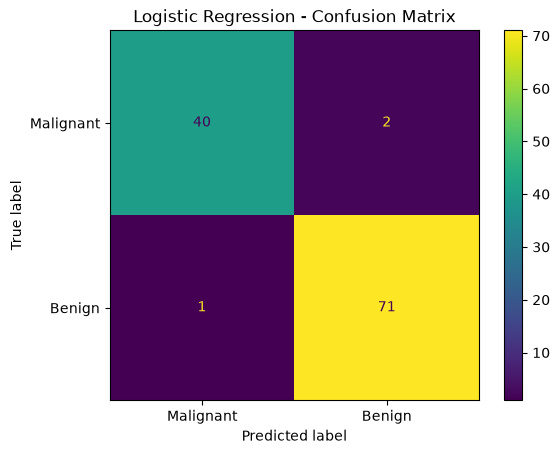

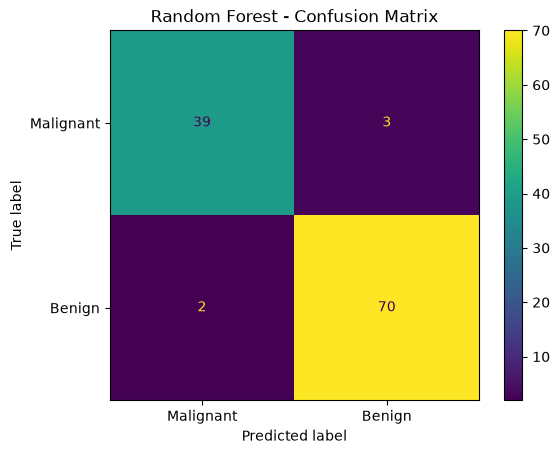

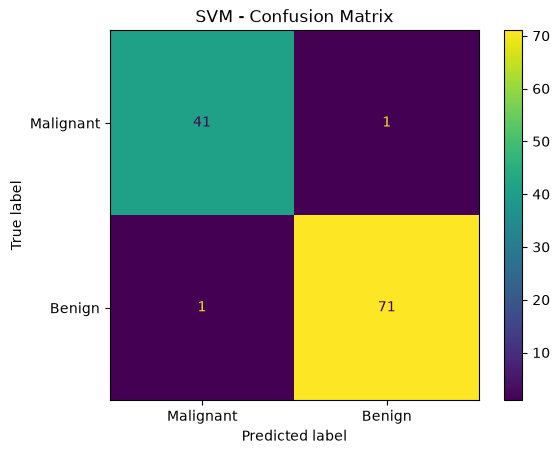

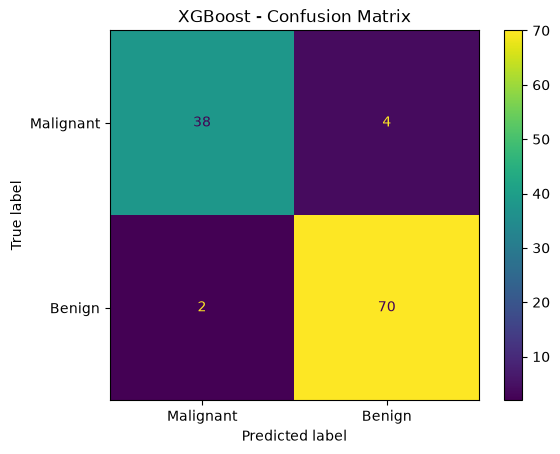

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

models = {
    "Logistic Regression": y_pred_tuned,
    "Random Forest": y_pred_rf_tuned,
    "SVM": y_pred_svm_tuned,
    "XGBoost": y_pred_xgb_tuned
}

for model_name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )

    disp.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

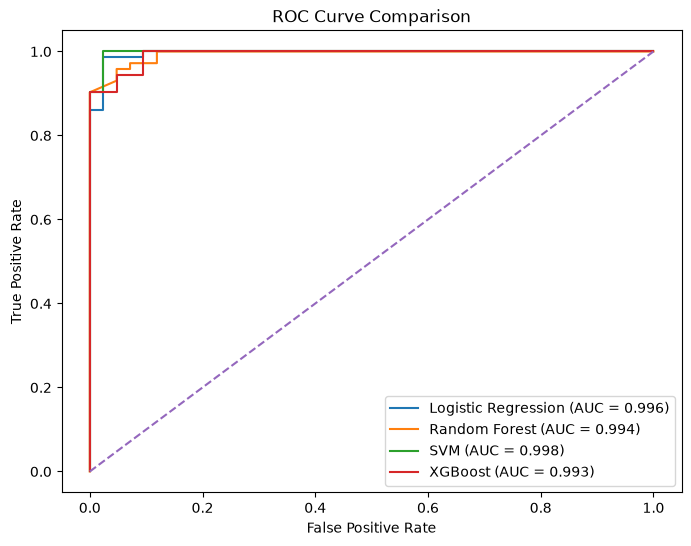

In [62]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

model_probabilities = {
    "Logistic Regression": y_prob_tuned,
    "Random Forest": y_prob_rf_tuned,
    "SVM": y_prob_svm_tuned,
    "XGBoost": y_prob_xgb_tuned
}

plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

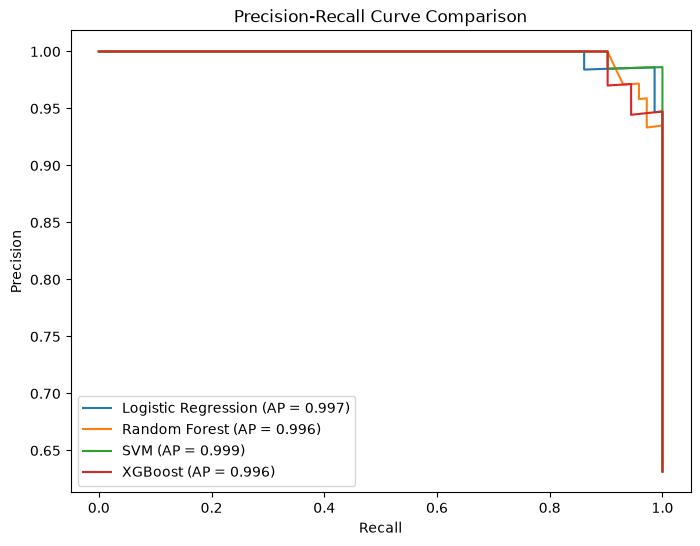

In [63]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():

    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    ap = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{model_name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.show()

In [64]:
comparison_percent.to_csv(
    "results/tables/model_comparison.csv",
    index=False
)

print("Model comparison saved.")

OSError: Cannot save file into a non-existent directory: 'results\tables'

In [65]:
from pathlib import Path

# Project root = notebooks folder-এর parent
project_root = Path.cwd().parent

tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("Tables folder:", tables_dir)
print("Figures folder:", figures_dir)

Tables folder: c:\Users\User\Desktop\medical tabular ml pipeline\results\tables
Figures folder: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures


In [66]:
comparison_percent.to_csv(
    tables_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [67]:
roc_path = figures_dir / "roc_curve_comparison.png"

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved:", roc_path)

<Figure size 640x480 with 0 Axes>

ROC curve saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\roc_curve_comparison.png


C:\Users\User\AppData\Local\Temp\ipykernel_14948\1546520567.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


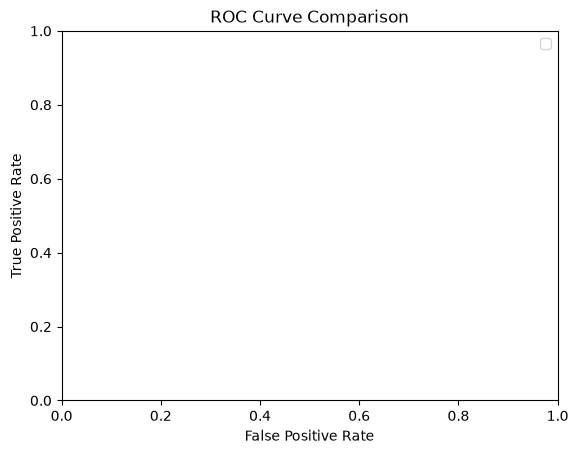

ROC curve saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\roc_curve_comparison.png


In [68]:
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

roc_path = figures_dir / "roc_curve_comparison.png"

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved:", roc_path)

In [69]:
pr_path = figures_dir / "pr_curve_comparison.png"

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR curve saved:", pr_path)


<Figure size 640x480 with 0 Axes>

PR curve saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\pr_curve_comparison.png


C:\Users\User\AppData\Local\Temp\ipykernel_14948\3995973451.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


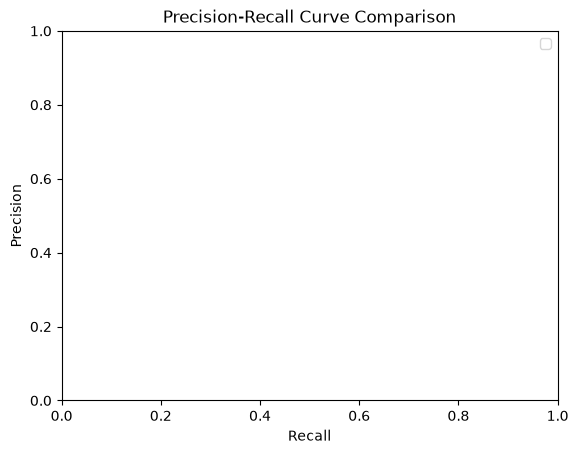

PR curve saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\pr_curve_comparison.png


In [70]:
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()

pr_path = figures_dir / "pr_curve_comparison.png"

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("PR curve saved:", pr_path)

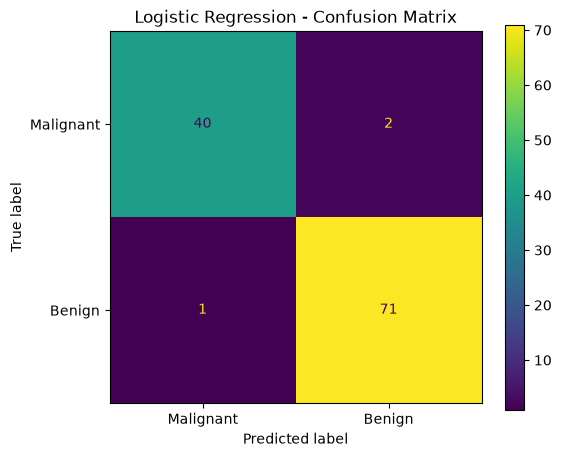

Saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\logistic_regression_confusion_matrix.png


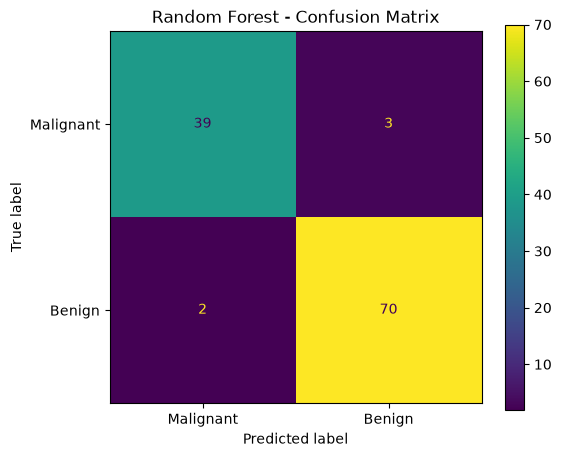

Saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\random_forest_confusion_matrix.png


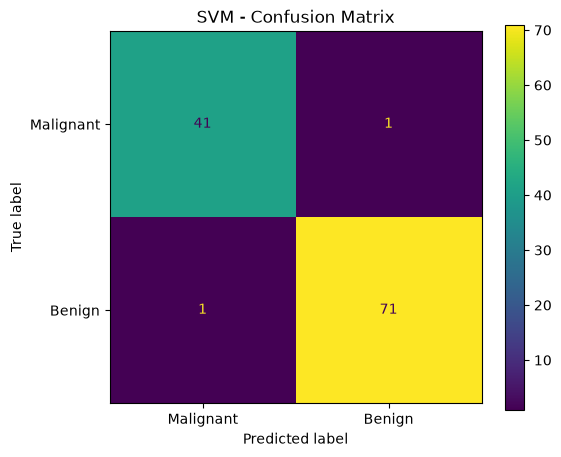

Saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\svm_confusion_matrix.png


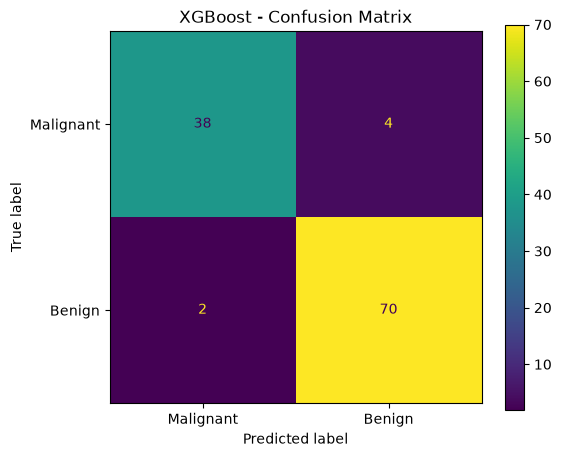

Saved: c:\Users\User\Desktop\medical tabular ml pipeline\results\figures\xgboost_confusion_matrix.png


In [71]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for model_name, predictions in models.items():

    cm = confusion_matrix(y_test, predictions)

    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )

    disp.plot(ax=ax)

    ax.set_title(f"{model_name} - Confusion Matrix")

    # filename বানানো
    filename = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    path = figures_dir / f"{filename}_confusion_matrix.png"

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", path)

In [72]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM",
        "XGBoost"
    ],

    "CV Accuracy Mean": [
        grid_search.best_score_,
        rf_grid.best_score_,
        svm_grid.best_score_,
        xgb_grid.best_score_
    ],

    "CV Accuracy Std": [
        cv_results["test_accuracy"].std(),
        rf_cv_results["test_accuracy"].std(),
        svm_cv_results["test_accuracy"].std(),
        xgb_cv_results["test_accuracy"].std()
    ],

    "Test Accuracy": [
        test_accuracy,
        accuracy_rf_tuned,
        accuracy_svm_tuned,
        accuracy_xgb_tuned
    ],

    "Precision": [
        test_precision,
        precision_rf_tuned,
        precision_svm_tuned,
        precision_xgb_tuned
    ],

    "Recall (Benign)": [
        test_recall,
        recall_rf_tuned,
        recall_svm_tuned,
        recall_xgb_tuned
    ],

    "Malignant Sensitivity": [
        40 / 42,
        39 / 42,
        41 / 42,
        38 / 42
    ],

    "Specificity": [
        test_specificity,
        specificity_rf_tuned,
        specificity_svm_tuned,
        specificity_xgb_tuned
    ],

    "F1": [
        test_f1,
        f1_rf_tuned,
        f1_svm_tuned,
        f1_xgb_tuned
    ],

    "ROC-AUC": [
        test_roc_auc,
        roc_auc_rf_tuned,
        roc_auc_svm_tuned,
        roc_auc_xgb_tuned
    ],

    "PR-AUC": [
        test_pr_auc,
        pr_auc_rf_tuned,
        pr_auc_svm_tuned,
        pr_auc_xgb_tuned
    ]
})

final_comparison

,Model,CV Accuracy Mean,CV Accuracy Std,Test Accuracy,Precision,Recall (Benign),Malignant Sensitivity,Specificity,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.982418,0.009829,0.973684,0.972603,0.986111,0.952381,0.952381,0.979310,0.995701,0.997428
1,Random Forest,0.962637,0.017855,0.956140,0.958904,0.972222,0.928571,0.928571,0.965517,0.993717,0.996216
2,SVM,0.975824,0.015541,0.982456,0.986111,0.986111,0.976190,0.976190,0.986111,0.997685,0.998610
3,XGBoost,0.971429,0.017855,0.947368,0.945946,0.972222,0.904762,0.904762,0.958904,0.992725,0.995809


In [73]:
final_comparison_percent = final_comparison.copy()

metric_columns = [
    "CV Accuracy Mean",
    "CV Accuracy Std",
    "Test Accuracy",
    "Precision",
    "Recall (Benign)",
    "Malignant Sensitivity",
    "Specificity",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

final_comparison_percent[metric_columns] = (
    final_comparison_percent[metric_columns] * 100
).round(2)

final_comparison_percent

,Model,CV Accuracy Mean,CV Accuracy Std,Test Accuracy,Precision,Recall (Benign),Malignant Sensitivity,Specificity,F1,ROC-AUC,PR-AUC
0,Logistic Regression,98.24,0.98,97.37,97.26,98.61,95.24,95.24,97.93,99.57,99.74
1,Random Forest,96.26,1.79,95.61,95.89,97.22,92.86,92.86,96.55,99.37,99.62
2,SVM,97.58,1.55,98.25,98.61,98.61,97.62,97.62,98.61,99.77,99.86
3,XGBoost,97.14,1.79,94.74,94.59,97.22,90.48,90.48,95.89,99.27,99.58


In [74]:
final_comparison_percent.to_csv(
    tables_dir / "model_comparison.csv",
    index=False
)

print("Final comparison table saved.")

Final comparison table saved.
